# Cesium (Cs) Agriculture site RF_Regression

Alex Koiter

## Load libraries

In [ ]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(randomForest)
  library(terra)
  library(caret)
  library(patchwork)
  library(sf)
  library(boot)
  library(optRF)
})

## Load data

In [ ]:
 attribute <- c("plan_curvature", "profile_curvature", "saga_wetness_index", "catchment_area", "relative_slope_position", "channel_network_distance", "elevation")

data <- read_csv(here::here("./notebooks/ag_terrain_data.csv"), show_col_types = FALSE) %>%
  select("x", "y", "cs", any_of(attribute))

## Map soil property

In [ ]:
temp_rast <- rast(data)
crs(x = temp_rast, warn=FALSE) <- "epsg:26914"

coords <- read_csv(here::here("./notebooks/coords.csv"), show_col_types = FALSE) %>% 
  st_as_sf(coords = c("long", "lat"),  crs = 4326) %>%
  st_transform(crs = 26914)

p1<- ggplot() +
  tidyterra::geom_spatraster(data = temp_rast, aes(fill = cs)) +
  scale_fill_viridis_c(name = "Cs", breaks = seq(4, 9, 1)) +
  geom_sf(data = filter(coords, site == "Agriculture")) +
  theme_bw(base_size = 12) +
  theme(axis.title = element_blank(),
        axis.text = element_blank(),
        axis.ticks = element_blank(),
        legend.position = "bottom") +
  scale_y_continuous(expand = c(0,0)) +
  scale_x_continuous(expand = c(0,0)) +
  ggspatial::annotation_scale(location = "bl") +
  ggspatial::annotation_north_arrow(location = "br")

p2 <- ggplot() +
  tidyterra::geom_spatraster(data = temp_rast, aes(fill = elevation)) +
  scale_fill_viridis_c(name = "Elevation (m)", option = "inferno") +
  geom_sf(data = filter(coords, site == "Agriculture")) +
  theme_bw(base_size = 12) +
  theme(axis.title = element_blank(),
        axis.text = element_blank(),
        axis.ticks = element_blank(),
        legend.position = "bottom") +
  scale_y_continuous(expand = c(0,0)) +
  scale_x_continuous(expand = c(0,0)) +
  ggspatial::annotation_scale(location = "bl") +
  ggspatial::annotation_north_arrow(location = "br")

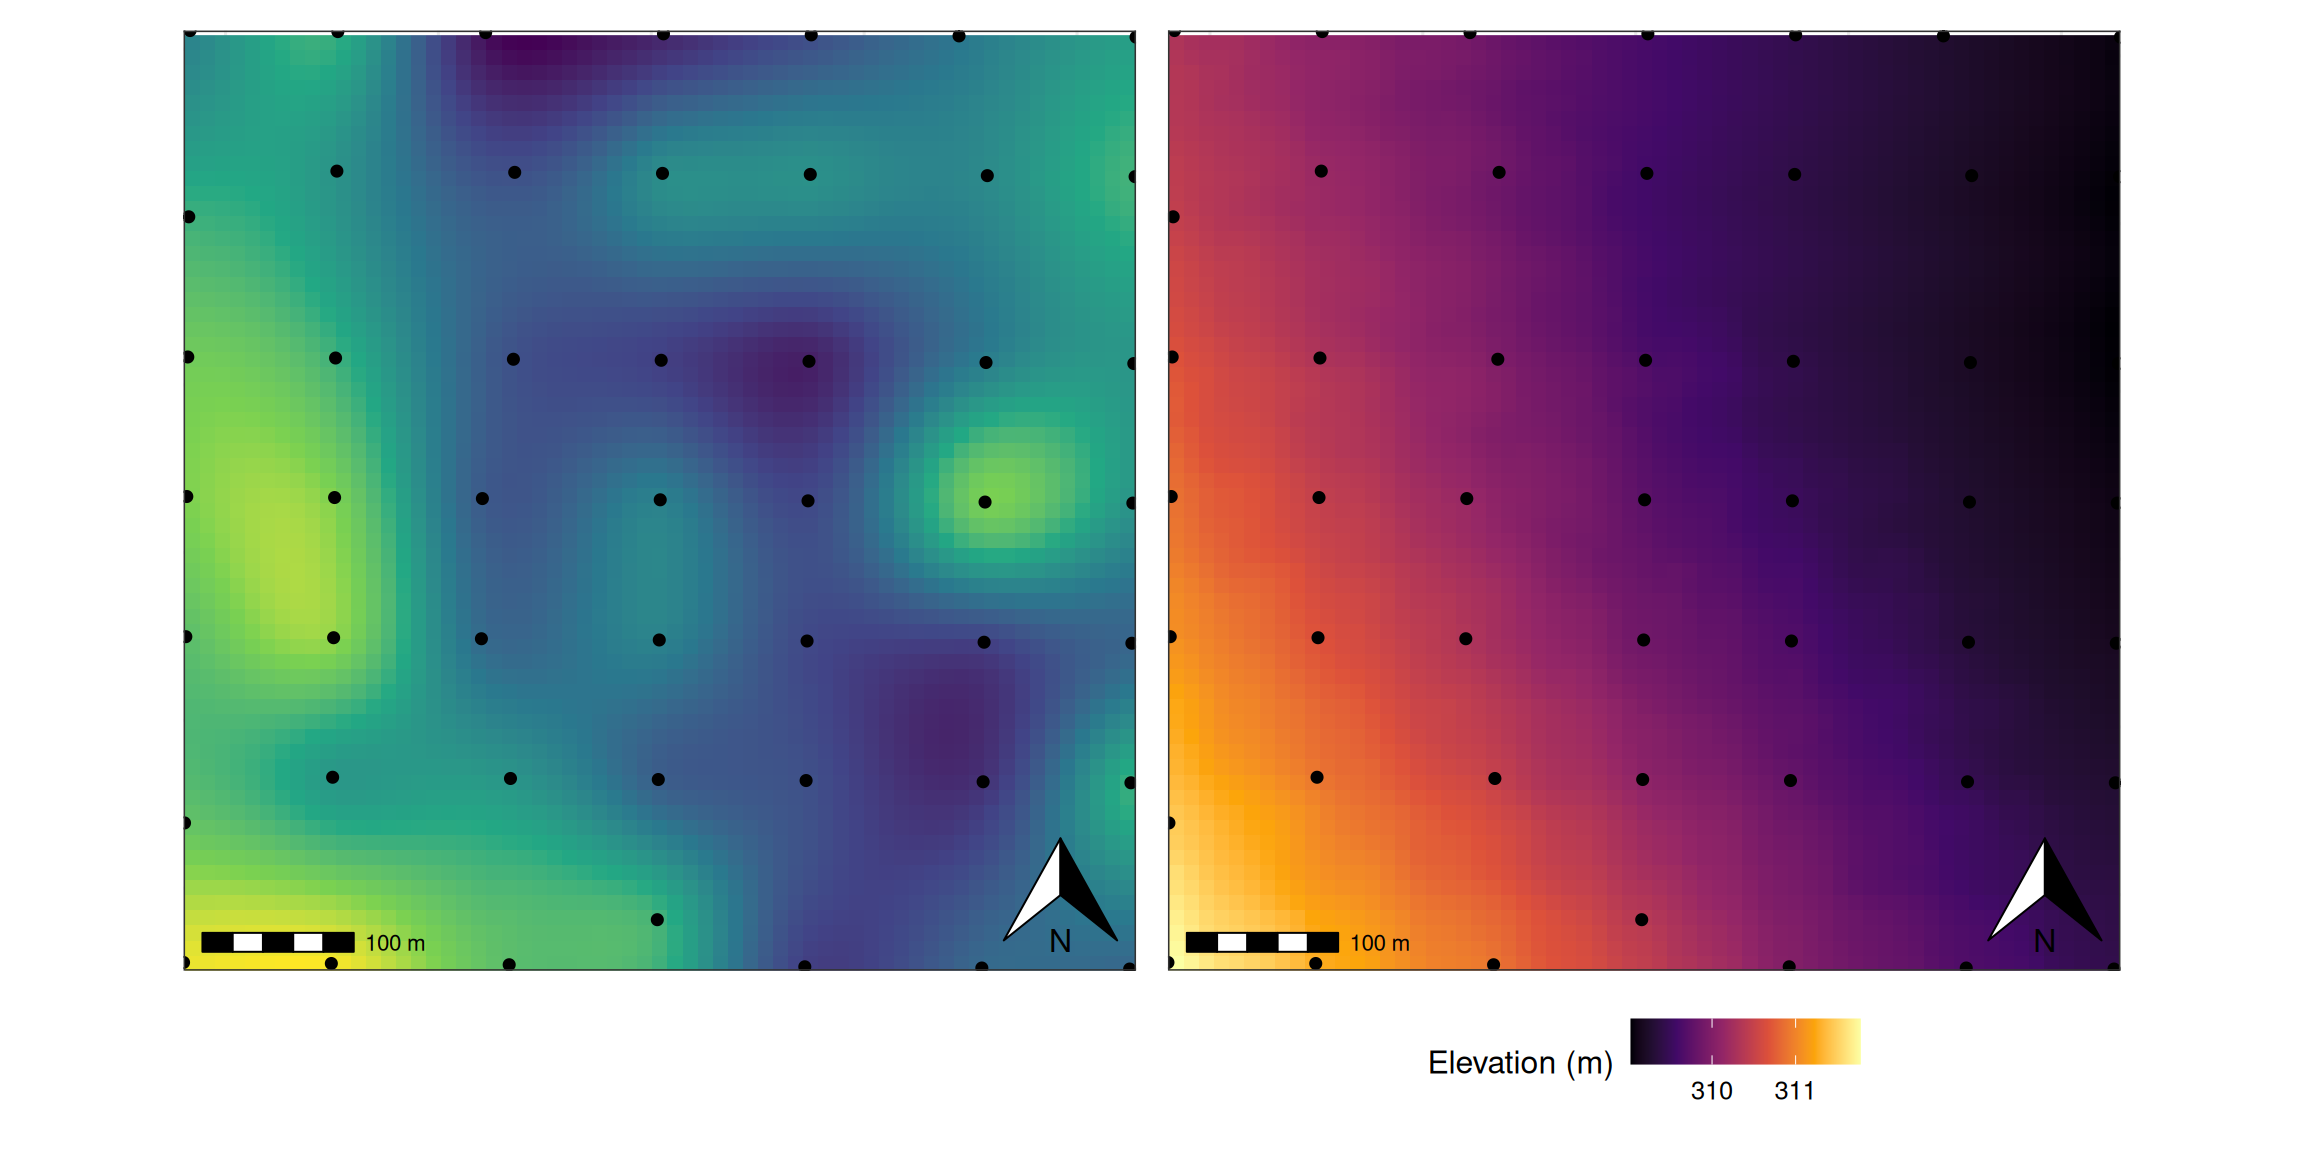

In [ ]:
#| fig-width: 12
#| fig-asp: 0.5
p1+p2  

## RF model original 49 data points

In [ ]:
x <- "cs"
data <- orig_data <- read_csv(here::here("./notebooks/ag_data_49.csv")) |>
  select(x, any_of(attribute))

Rows: 49 Columns: 22
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (22): plan_curvature, profile_curvature, saga_wetness_index, catchment_a...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.

ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(x)

  # Now:
  data %>% select(all_of(x))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.

### Training and test data sets

In [ ]:
set.seed(222)
ind <- sample(2, nrow(data), replace = TRUE, prob = c(0.7, 0.3))
train <- data[ind==1,]
test <- data[ind==2,]

### Feature selection

In [ ]:
features <- usdm::vifstep(data.frame(select(train, all_of(attribute))), th = 10)

train <- train %>% 
  usdm::exclude(features)

Warning in usdm::exclude(., features): No variable to exclude!

Warning in usdm::exclude(., features): No variable to exclude!

### Tune RF

mtry = 2  OOB error = 0.01286259 
Searching left ...
mtry = 1    OOB error = 0.014157 
-0.1006335 0.05 
Searching right ...
mtry = 4    OOB error = 0.01057003 
0.1782345 0.05 
mtry = 7    OOB error = 0.01070105 
-0.01239535 0.05 

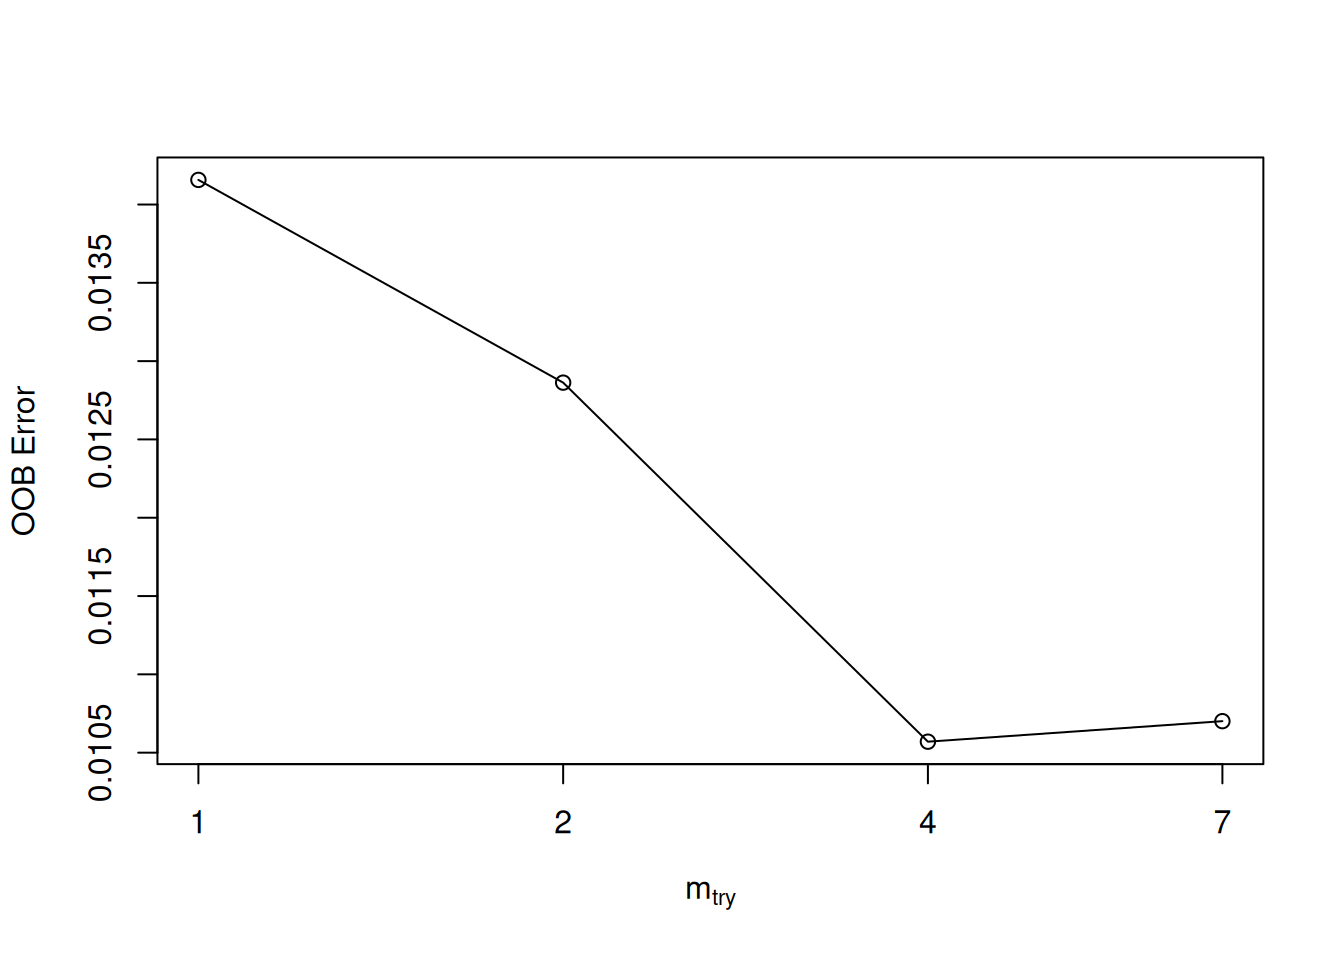

In [ ]:
my_mtry <- tuneRF(y = train[[x]], x = train[attribute], trace = TRUE, plot = TRUE) |>
  data.frame() |>
  slice(which.min(OOBError)) |>
  pull(mtry)

### Fit Model


Call:
 randomForest(formula = cs ~ ., data = train, ntree = 500, keep.forest = TRUE,      importance = TRUE, mtry = my_mtry) 
               Type of random forest: regression
                     Number of trees: 500
No. of variables tried at each split: 4

          Mean of squared residuals: 0.009733706
                    % Var explained: 57.43

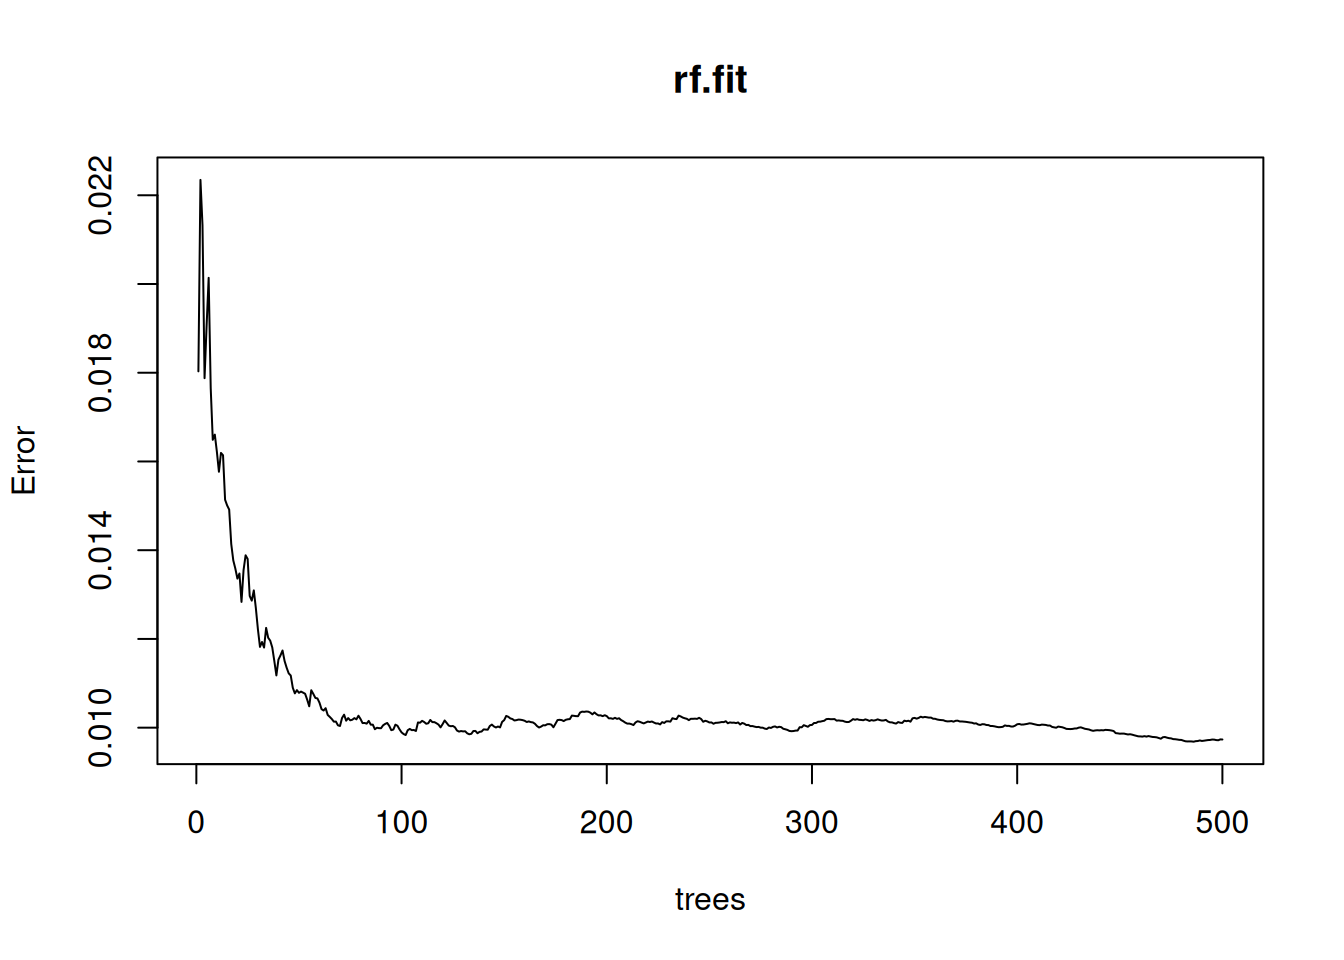

In [ ]:
rf.fit <- randomForest(cs ~ ., data = train, 
                       ntree = 500, keep.forest = TRUE, importance = TRUE, mtry = my_mtry)
rf.fit

### Test Model

Uses the RF model to predict the test dataset. We compare predicted against actual

In [ ]:
obs <- test[[x]]
pred <- prediction <- predict(rf.fit, newdata = test)

example <- data.frame(obs, pred)

# Define a function to compute R-squared from bootstrap samples
rsq <- function(formula, data, indices) {
  d <- data[indices, ]  # Allows boot to select resampled cases
  fit <- lm(formula, data = d)
  return(summary(fit)$r.square)
}

# Perform bootstrapping with 1000 replications
# Example: predicting mpg from wt and disp
results <- boot(
  data = example,
  statistic = rsq,
  R = 1000,
  formula = pred ~ obs
)

# View bootstrap results
test2 <- boot.ci(results, type = "perc")

r_sq_mean <- mean(test2$t)
r_sq_mean

[1] 0.2874894

[1] 0.6408428

[1] 0.03416721

In [ ]:
# Set seed for reproducibility
set.seed(123)


# Define function to compute MSE on bootstrap samples
mse_boot <- function(data, indices) {
  d <- data[indices, ]  # Bootstrap sample
  mse <- mean((d$obs - d$pred)^2)
  return(mse)
}

# Bootstrap with 1000 replications
boot_results <- boot(data = example, statistic = mse_boot, R = 1000)

# Get percentile confidence interval
boot_ci <- boot.ci(boot_results, type = "perc")

# Extract lower and upper limits
mse_mean <- mean(boot_results$t)
mse_mean

[1] 0.01278924

[1] 0.005509096

[1] 0.02155995


Call:
lm(formula = pred ~ obs, data = test_plot)

Residuals:
      Min        1Q    Median        3Q       Max 
-0.141400 -0.057153 -0.006403  0.070538  0.152087 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept)   0.4425     0.1335   3.315  0.00471 **
obs           0.4163     0.1692   2.460  0.02651 * 
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.08878 on 15 degrees of freedom
Multiple R-squared:  0.2875,    Adjusted R-squared:   0.24 
F-statistic: 6.052 on 1 and 15 DF,  p-value: 0.02651

Registered S3 methods overwritten by 'ggpp':
  method                  from   
  heightDetails.titleGrob ggplot2
  widthDetails.titleGrob  ggplot2

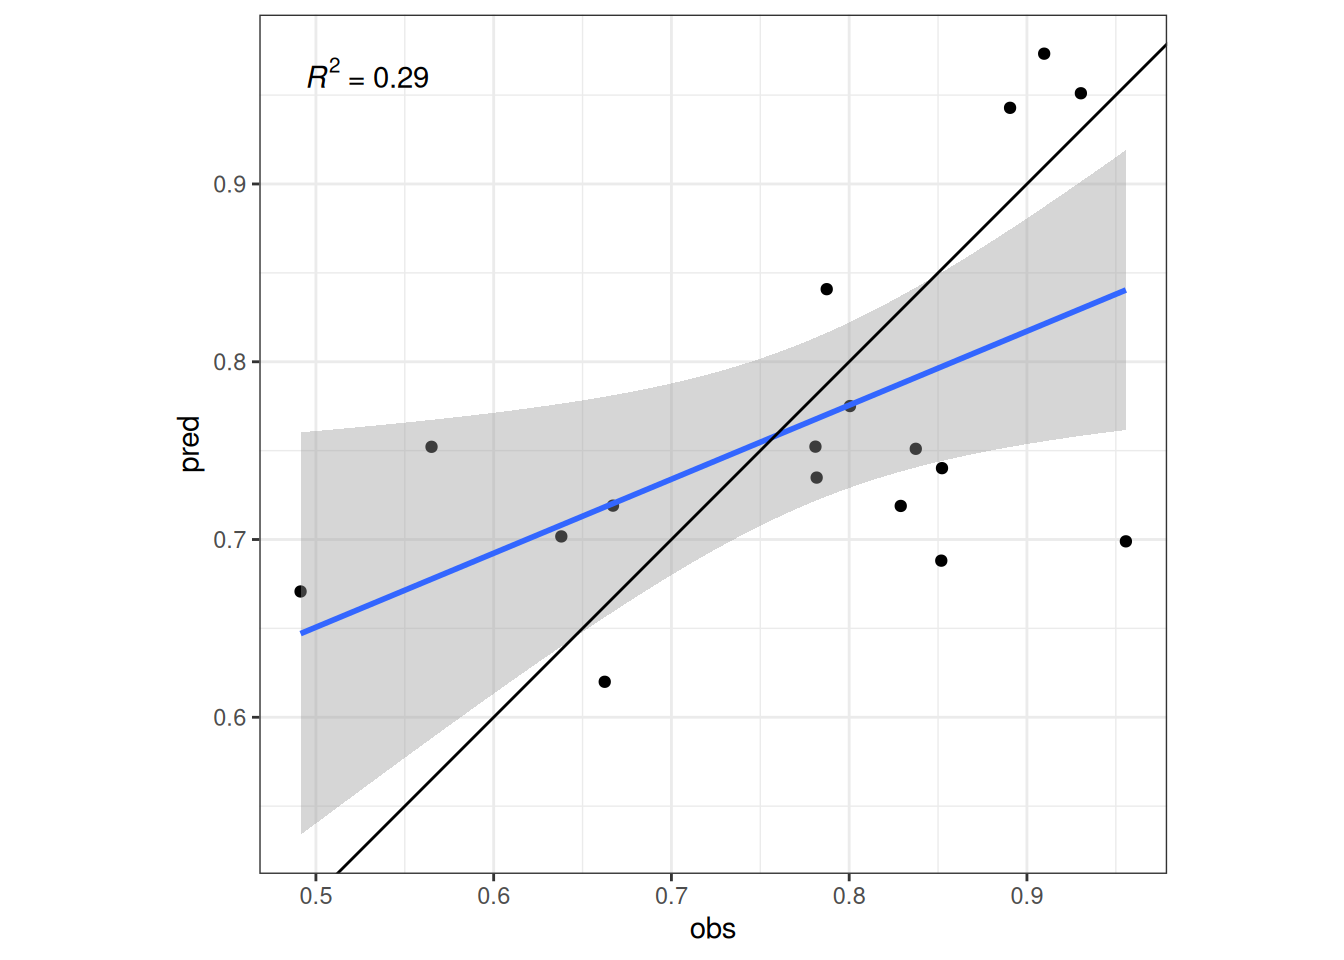

        mse
1 0.0126083

In [ ]:
prediction <- predict(rf.fit, newdata = test)
test_plot <- data.frame(pred = prediction, obs = test[[x]])

r_sq <- summary(lm(pred~obs, data = test_plot))
r_sq

## Importance

In [ ]:
# Varibale Importance stability

set.seed(123)

stability_result = measure_stability(y = train[[x]], X=train[,-1], num.trees=500, method = "importance", alpha = 3/8)

Analysing random forest with 500 trees, progress: 10% 
Analysing random forest
with 500 trees, progress: 20% 
Analysing random forest with 500 trees, progress:
30% 
Analysing random forest with 500 trees, progress: 40% 
Analysing random
forest with 500 trees, progress: 50% 
Analysing random forest with 500 trees,
progress: 60% 
Analysing random forest with 500 trees, progress: 70% 
Analysing
random forest with 500 trees, progress: 80% 
Analysing random forest with 500
trees, progress: 90% 
Analysing random forest with 500 trees, progress: 100%

[1] 0.9913087

In [ ]:
ImpData <- as.data.frame(importance(rf.fit)) %>%
  mutate(Var.Names = row.names(.)) %>%
 `row.names<-`(as.character(1:nrow(importance(rf.fit))))

### Top based on IncNodePurity

In [ ]:
slice_max(ImpData,order_by = IncNodePurity, n = 10)

     %IncMSE IncNodePurity                Var.Names
7 15.5898927    0.23407459                elevation
3 14.7224527    0.20943265       saga_wetness_index
5  9.7770025    0.08092467  relative_slope_position
6  6.4850228    0.07249439 channel_network_distance
2  2.5955913    0.04429029        profile_curvature
4  0.1196538    0.02644704           catchment_area
1  0.7834297    0.01744589           plan_curvature

In [ ]:
p1 <- ggplot(slice_max(ImpData,order_by = IncNodePurity, n = 10), aes(x = fct_reorder(Var.Names, IncNodePurity), y = IncNodePurity)) +
  geom_segment(aes(x = fct_reorder(Var.Names, IncNodePurity), xend = fct_reorder(Var.Names, IncNodePurity), y = 0, yend = IncNodePurity), color="skyblue") +
  geom_point(aes(size = `%IncMSE`), color = "blue", alpha = 0.6) +
  theme_bw() +
  coord_flip() +
  labs(x = "Terrain Attribute", y = "IncNodePurity") +
  theme(legend.position="bottom")

### Top 10 based on %IncMSE

In [ ]:
slice_max(ImpData,order_by = `%IncMSE`, n = 10)

     %IncMSE IncNodePurity                Var.Names
7 15.5898927    0.23407459                elevation
3 14.7224527    0.20943265       saga_wetness_index
5  9.7770025    0.08092467  relative_slope_position
6  6.4850228    0.07249439 channel_network_distance
2  2.5955913    0.04429029        profile_curvature
1  0.7834297    0.01744589           plan_curvature
4  0.1196538    0.02644704           catchment_area

In [ ]:
p2<- ggplot(slice_max(ImpData,order_by = `%IncMSE`, n = 10), aes(x = fct_reorder(Var.Names, `%IncMSE`), y = `%IncMSE`)) +
  geom_segment(aes(x = fct_reorder(Var.Names, `%IncMSE`), xend = fct_reorder(Var.Names, `%IncMSE`), y = 0, yend = `%IncMSE`), color="skyblue") +
  geom_point(aes(size = IncNodePurity), color = "blue", alpha = 0.6) +
  theme_bw() +
  coord_flip() +
  labs(x = "Terrain Attribute", y = "%IncMSE") +
  theme(legend.position="bottom")

### Combined

In [ ]:
#| label: Original data
#| fig-cap: Ag Cs 
p1+p2

## Write data

In [ ]:
importance_data <- ImpData %>%
  mutate(MSE_rank = rank(-`%IncMSE`)) %>%
  mutate(Purity_rank = rank(-IncNodePurity)) %>%
  mutate(site = "Agriculture",
        property = "Cs")

if(file.exists(here::here("./notebooks/importance_data_49.csv"))) {
  importance_data_final <- read_csv(here::here("./notebooks/importance_data_49.csv")) |>
    rows_upsert(importance_data, by = c("MSE_rank", "site", "property")) 
} else importance_data_final <- importance_data

Rows: 161 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (3): Var.Names, site, property
dbl (4): %IncMSE, IncNodePurity, MSE_rank, Purity_rank

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.

Rows: 23 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): site, property
dbl (4): MSE, Var_exp, R2, mse_test

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.

Rows: 23 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): MSE_test, R2_test, site, property
dbl (1): stability

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.